# Phase 1 – Part B: Supervised Learning

## Logistic Regression

### 1. Model Selection Rationale
Logistic Regression was selected as a baseline model because this is a binary classification problem.

The dataset is tabular and contains a relatively small number of health-related features compared with the large number of observations. The features include binary, ordinal, and numeric variables, and the relevant numeric features were standardized during preprocessing.

Logistic Regression is computationally efficient, produces class probabilities, and is highly interpretable through its coefficients. This makes it useful as a baseline model and appropriate for a healthcare screening decision-support system.

However, Logistic Regression assumes a linear relationship between the input features and the log-odds of the target class. Therefore, it may not capture complex non-linear relationships or interactions as effectively as tree-based models such as Random Forest or XGBoost.
### 2. Data Preparation
The preprocessed and scaled training and testing datasets were used. The target variable is `Diabetes_binary`.



In [ ]:
import pandas as pd
import os
import numpy as np


# Create output folders before saving any results
for d in ["models", "evaluation_results", "plots"]:
    os.makedirs(d, exist_ok=True)

In [ ]:


train_df = pd.read_csv("../Dataset/train_data_scaled.csv")
test_df = pd.read_csv("../Dataset/test_data_scaled.csv")

train_df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1.0,1.0,1.0,1.522681,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,1.023248,2.085779,0.795089,0.0,0.0,-0.560250,0.096651,0.620802,1.0
1,1.0,1.0,1.0,2.574384,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.120930,3.179636,0.795089,1.0,0.0,-0.910212,-1.848155,-2.132254,1.0
2,0.0,0.0,1.0,-0.881209,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,-0.781388,-0.101935,-0.585930,0.0,0.0,-0.560250,0.096651,0.620802,0.0
3,1.0,1.0,1.0,1.823168,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.120930,-0.466554,-0.585930,0.0,0.0,0.139674,0.096651,0.620802,1.0
4,0.0,0.0,1.0,0.771466,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.120930,0.262684,-0.585930,1.0,0.0,0.139674,0.096651,0.161959,1.0


### Dataset Overview


In [80]:
# Display basic information about the prepared datasets
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nClass distribution in training data:")
print(train_df["Diabetes_binary"].value_counts(normalize=True))

print("\nNumber of features:", train_df.shape[1] - 1)

Training shape: (55245, 22)
Testing shape: (13812, 22)

Class distribution in training data:
Diabetes_binary
1.0    0.508227
0.0    0.491773
Name: proportion, dtype: float64

Number of features: 21


In [81]:
X_train = train_df.drop("Diabetes_binary", axis=1)
y_train = train_df["Diabetes_binary"]

X_test = test_df.drop("Diabetes_binary", axis=1)
y_test = test_df["Diabetes_binary"]

### 3. Model Training

In [82]:
from sklearn.linear_model import LogisticRegression

# Create the baseline Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Generate probabilities for class 1
y_prob = model.predict_proba(X_test)[:, 1]

### 4. Model Evaluation
The model was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix.

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7457283521575442
Precision: 0.7384448069603046
Recall: 0.7737891737891738


F1-score: 0.7557039510294936
ROC-AUC: 0.8183713494005013

Classification Report:
              precision    recall  f1-score   support

         0.0       0.75      0.72      0.73      6792
         1.0       0.74      0.77      0.76      7020

    accuracy                           0.75     13812
   macro avg       0.75      0.75      0.75     13812
weighted avg       0.75      0.75      0.75     13812


Confusion Matrix:
[[4868 1924]
 [1588 5432]]


### 5. Cross-Validation
A 5-fold cross-validation was applied to evaluate model stability across different subsets of the training data.

In [84]:
from sklearn.model_selection import cross_validate

# Evaluate model stability using 5-fold cross-validation
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results = cross_validate(
    LogisticRegression(max_iter=1000, random_state=42),
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

for metric in scoring:
    print(metric, cv_results[f"test_{metric}"].mean())

accuracy 0.7455697348176306
precision 0.7393533089664377
recall 0.7713074398804587
f1 0.7549890958827129
roc_auc 0.8210423147247579


### 6. Hyperparameter Tuning
GridSearchCV was used to tune the `C` and `solver` hyperparameters.

In [85]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid,
    cv=5,
    scoring="f1"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

Best Parameters: {'C': 0.1, 'solver': 'lbfgs'}
Best CV F1: 0.7550670350821151


### Hyperparameter Tuning Results

GridSearchCV identified `C = 0.1` and `solver = lbfgs` as the best hyperparameter combination based on the F1-score.

The best cross-validation F1-score was approximately 0.755. This result is very close to the baseline model performance, indicating that hyperparameter tuning did not significantly improve the Logistic Regression model.

In [86]:
best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

### 7. Baseline vs Tuned Model Comparison

In [87]:
# Compare baseline and tuned Logistic Regression performance
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Baseline": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ],
    "Tuned": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned),
        roc_auc_score(y_test, y_prob_tuned)
    ]
})

comparison

,Metric,Baseline,Tuned
0,Accuracy,0.745728,0.745656
1,Precision,0.738445,0.738344
2,Recall,0.773789,0.773789
3,F1-score,0.755704,0.755651
4,ROC-AUC,0.818371,0.818398


### 8. Tuned Model Evaluation

In [88]:
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1-score:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

Accuracy: 0.7456559513466551
Precision: 0.7383444338725024
Recall: 0.7737891737891738
F1-score: 0.755651387633025
ROC-AUC: 0.8183975659314293


The tuned model achieved performance almost identical to the baseline model. The F1-score remained approximately 0.756 and the ROC-AUC remained approximately 0.818. This suggests that the baseline Logistic Regression model was already stable and not highly sensitive to the tested hyperparameters.

### 9. Feature Coefficients and Interpretability

In [89]:
# Extract coefficients from the tuned Logistic Regression model
coef = pd.Series(
    best_model.coef_[0],
    index=X_train.columns
).sort_values()

# Convert coefficients to odds ratios
coef_table = pd.DataFrame({
    "Coefficient": coef,
    "Odds_Ratio": np.exp(coef)
}).round(3)

print("Top 5 features increasing class 1 prediction:")
print(
    coef_table
    .sort_values("Coefficient", ascending=False)
    .head(5)
)

print("\nTop 5 features decreasing class 1 prediction:")
print(
    coef_table
    .sort_values("Coefficient")
    .head(5)
)

Top 5 features increasing class 1 prediction:
           Coefficient  Odds_Ratio
CholCheck        1.304       3.683
HighBP           0.702       2.018
GenHlth          0.629       1.875
HighChol         0.579       1.784
BMI              0.547       1.728

Top 5 features decreasing class 1 prediction:
                   Coefficient  Odds_Ratio
HvyAlcoholConsump       -0.719       0.487
Income                  -0.120       0.887
Veggies                 -0.081       0.922
PhysHlth                -0.078       0.925
Education               -0.044       0.957


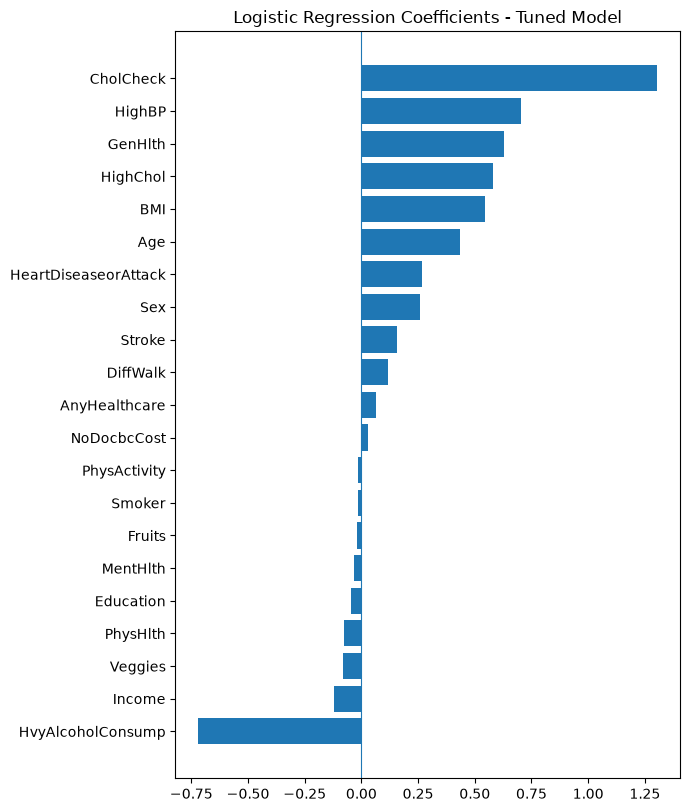

In [90]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(7, 0.32 * len(coef) + 1.5)
)

ax.barh(
    coef.index,
    coef.values
)

ax.axvline(0, linewidth=0.8)

ax.set_title("Logistic Regression Coefficients - Tuned Model")

plt.tight_layout()

plt.savefig(
    "plots/logistic_regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The tuned Logistic Regression model shows that `CholCheck`, `HighBP`, `GenHlth`, `HighChol`, `BMI`, and `Age` have some of the strongest positive coefficients, meaning they push the model more toward predicting class 1.

Features with coefficients close to zero have a smaller effect on the prediction, while negative coefficients push the prediction more toward class 0. These coefficients describe the model's learned associations and should not be interpreted as causal relationships.

### 10. Confusion Matrix

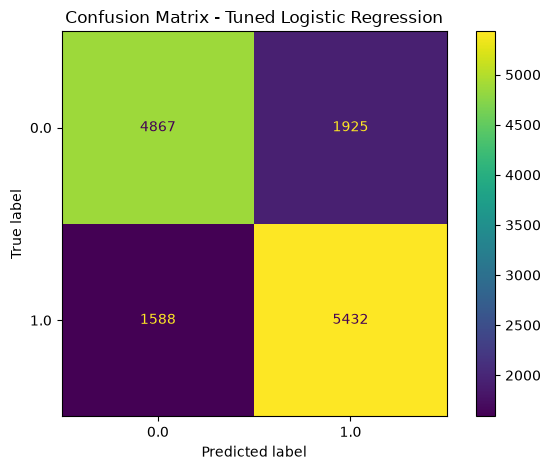

In [91]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned
)

plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.tight_layout()

plt.savefig(
    "plots/logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11. Misclassification Analysis

In [92]:
# Extract confusion matrix values
cm = confusion_matrix(y_test, y_pred_tuned)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 4867
False Positives: 1925
False Negatives: 1588
True Positives: 5432


In this healthcare screening context, false negatives are especially important because they represent individuals who belong to the positive screening class but were incorrectly classified as negative. Missing these cases may prevent at-risk individuals from being prioritized for further clinical assessment. Therefore, reducing false negatives and maintaining a high recall is particularly important for this system.

In [93]:
# Compare missed positives (FN) with correctly detected positives (TP)
errors = X_test.copy()

errors["y_true"] = y_test.values
errors["y_pred"] = y_pred_tuned

fn_cases = errors[
    (errors["y_true"] == 1) &
    (errors["y_pred"] == 0)
]

tp_cases = errors[
    (errors["y_true"] == 1) &
    (errors["y_pred"] == 1)
]

fn_vs_tp = pd.DataFrame({
    "FN_mean": fn_cases[X_test.columns].mean(),
    "TP_mean": tp_cases[X_test.columns].mean()
})

fn_vs_tp["Difference"] = (
    fn_vs_tp["FN_mean"] -
    fn_vs_tp["TP_mean"]
)

fn_vs_tp = fn_vs_tp.reindex(
    fn_vs_tp["Difference"]
    .abs()
    .sort_values(ascending=False)
    .index
)

fn_vs_tp.head(10)

,FN_mean,TP_mean,Difference
GenHlth,-0.372277,0.596839,-0.969116
BMI,-0.287143,0.451259,-0.738402
Income,0.233617,-0.323661,0.557278
PhysHlth,-0.199801,0.324550,-0.524351
HighBP,0.370907,0.870029,-0.499123
Age,-0.078721,0.377793,-0.456514
Education,0.171969,-0.235599,0.407568
HighChol,0.379723,0.749816,-0.370093
DiffWalk,0.113350,0.454161,-0.340810
MentHlth,-0.133851,0.135058,-0.268909


The misclassification analysis shows that the largest differences between false negative and true positive cases appeared in `GenHlth`, `BMI`, `Income`, `PhysHlth`, `HighBP`, and `Age`.

In particular, false negative cases tended to have lower standardized values for `GenHlth`, `BMI`, `PhysHlth`, `HighBP`, and `Age` compared with correctly detected positive cases. This suggests that positive cases with less obvious risk patterns may be more difficult for the Logistic Regression model to identify.

### 12. ROC Curve

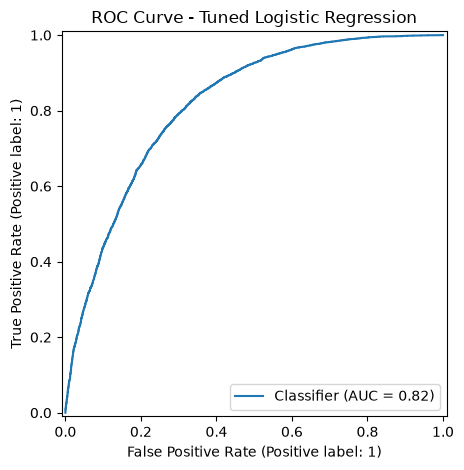

In [94]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_tuned
)

plt.title("ROC Curve - Tuned Logistic Regression")
plt.tight_layout()

# Save the ROC curve plot
plt.savefig(
    "plots/logistic_regression_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 13. Strengths and Limitations

**Strengths:** Simple, fast, interpretable, and suitable as a baseline model for binary classification.

**Limitations:** May not capture complex non-linear relationships between health indicators as effectively as tree-based models such as Random Forest or XGBoost.

### 14. Save Model and Evaluation Results
The trained model, evaluation results, and visualizations were saved according to the project repository structure.

In [95]:
import joblib

# Save the tuned Logistic Regression model
joblib.dump(
    best_model,
    "models/logistic_regression_model.pkl"
)

# Save baseline vs tuned comparison
comparison.to_csv(
    "evaluation_results/logistic_regression_comparison.csv",
    index=False
)

print("Model and evaluation results saved successfully.")

Model and evaluation results saved successfully.


### 15. Conclusion

The tuned Logistic Regression model achieved approximately 74.6% accuracy, 75.6% F1-score, and 0.82 ROC-AUC on the test set.

The baseline and tuned models produced nearly identical results, suggesting that hyperparameter tuning had limited impact on performance. The model showed stable cross-validation performance and provided good interpretability through its coefficients.

However, its linear structure may limit its ability to capture complex relationships between health indicators. The final model selection will therefore be determined after comparing Logistic Regression with Random Forest and XGBoost.

### 16. Trade-offs

- **Accuracy:** Moderate.
- **Interpretability:** High because model coefficients can be directly inspected.
- **Computational Cost:** Low compared with more complex tree-based models.

### 17. Next Steps for Phase 2

- Use predicted probabilities as confidence scores in the dashboard.
- Evaluate how changing the classification threshold affects false negatives and false positives.
- Use important model coefficients as explanatory information.
- Compare model performance across clusters created during the unsupervised learning phase.
- Provide prediction probability and key features to the Generative AI component for explanation generation.